# Module A: Price Advisor
Goal: predict adr (nightly rate) for a booking. 

Intuition: you’re teaching a model how a revenue manager prices rooms. Room type, month, party size and lead time all push the rate up or down. The business decision is the suggested nightly rate for a new booking.



## 0. Setup

In [1]:
import sys
sys.path.insert(0, "..")          # project root, so `src` can be found

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from src._01_code.features import build_preprocessor

In [2]:
# --------- Configarations -----------
RANDOM_STATE = 42
TEST_SIZE = 0.2
TARGETS = ["is_canceled", "adr"]

df = pd.read_csv("../data/clean/hotel_clean.csv")


In [3]:
# Train test split 

train_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["is_canceled"], random_state=RANDOM_STATE
)

#Keep bookings with a real price
n_train_before, n_test_before = len(train_df), len(test_df)
train_df = train_df[train_df["adr"] > 0 ]
test_df = test_df[test_df["adr"] > 0 ]
print (f"train: {n_train_before:,} -> {len(train_df):,} | test: {n_test_before:,} -> {len(test_df):,} ")

# Features exclude BOTH targets: adr is the target for Module A, is_canceled for Module B
X_train = train_df.drop(columns=TARGETS)
X_test = test_df.drop(columns=TARGETS)
y_train, y_test = train_df["adr"], test_df["adr"]

y_train, y_test = train_df["adr"], test_df["adr"]

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()



train: 69,096 -> 68,280 | test: 17,275 -> 17,039 


In [4]:
# Helper funtions & pipeline configration

def make_pipe(model):
    return Pipeline([
        ("prep", build_preprocessor(num_cols, cat_cols)),
        ("model", model),
    ])

def cv_score(name, pipe):
    cv = cross_validate(
        pipe, X_train, y_train, cv=5, n_jobs=-1,
        scoring={"mae": "neg_mean_absolute_error",
                 "rmse": "neg_root_mean_squared_error",
                 "r2": "r2"},
    )
    return {"model": name,
            "MAE": -cv["test_mae"].mean(),    # sklearn negates errors so "higher is better"
            "RMSE": -cv["test_rmse"].mean(),
            "R2": cv["test_r2"].mean()}

## 1. Baseline & Linear regression model 

In [5]:
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
}

results = [cv_score(name, make_pipe(m)) for name, m in models.items()]
leaderboard = pd.DataFrame(results).sort_values("MAE")
leaderboard

,model,MAE,RMSE,R2
1,Linear Regression,21.272858,28.913133,0.669932
0,Mean baseline,38.825589,50.328169,-0.000033


* R² = 0.66 means the model explains about 66% of the variation in ADR. The hotel can read it as “these booking details (dates, room type, guests, lead time, and so on) account for roughly two-thirds of why prices differ.” The other 34% is what the model can’t explain yet. It could be non-linear effects, features we don’t have (events, competitors’ prices) or plain noise.
* RMSE is  above than the MAE. Because squaring punishes big misses, so this gap tells you some bookings have prices far from the average (expensive peak-season rooms, for example)

Text(0, 0.5, 'predicted adr')

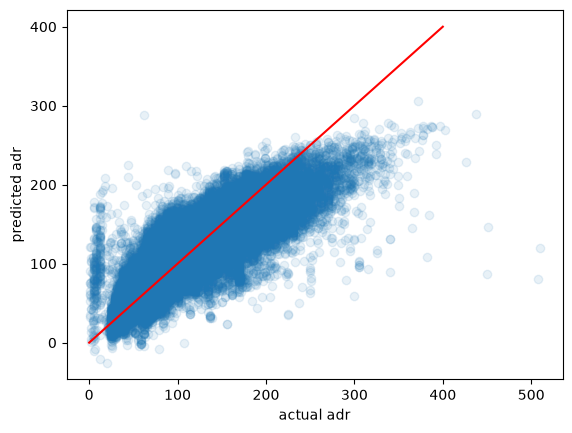

In [6]:
from sklearn.model_selection import cross_val_predict
pred = cross_val_predict(make_pipe(LinearRegression()), X_train, y_train, cv=5, n_jobs=-1)
plt.scatter(y_train, pred, alpha=0.1); plt.plot([0, 400], [0, 400], "r")
plt.xlabel("actual adr"); plt.ylabel("predicted adr")

In [7]:
pipe = make_pipe(LinearRegression())
pipe.fit(X_train, y_train)

names = pipe.named_steps["prep"].get_feature_names_out()
weights = pipe.named_steps["model"].coef_

coef_df = pd.DataFrame({"feature": names, "weight": weights})
coef_df["abs_weight"] = coef_df["weight"].abs()
coef_df.sort_values("abs_weight", ascending=False).head(10)

,feature,weight,abs_weight
104,cat__assigned_room_type_infrequent_sklearn,-129.917599,129.917599
24,cat__arrival_date_month_December,56.871310,56.871310
84,cat__distribution_channel_infrequent_sklearn,-56.172497,56.172497
79,cat__market_segment_infrequent_sklearn,-53.910987,53.910987
26,cat__arrival_date_month_January,-47.842788,47.842788
86,cat__reserved_room_type_B,-44.250113,44.250113
25,cat__arrival_date_month_February,-37.360728,37.360728
35,cat__meal_FB,37.048538,37.048538
92,cat__reserved_room_type_H,35.090128,35.090128
29,cat__arrival_date_month_March,-30.544154,30.544154


In [8]:
num_coef = coef_df[coef_df["feature"].str.startswith("num__")]
num_coef.sort_values("abs_weight", ascending=False).head(10)

,feature,weight,abs_weight
2,num__arrival_date_week_number,-22.270163,22.270163
1,num__arrival_date_year,10.918938,10.918938
0,num__lead_time,-10.017636,10.017636
6,num__adults,3.855852,3.855852
17,num__total_guests,3.596169,3.596169
3,num__arrival_date_day_of_month,3.138179,3.138179
18,num__is_family,2.079803,2.079803
7,num__children,1.544624,1.544624
8,num__babies,-1.169001,1.169001
9,num__is_repeated_guest,-1.044789,1.044789


In [9]:
(df["adr"] == 0).mean()
df.loc[df["adr"] == 0, "market_segment"].value_counts().head()

market_segment
Complementary    620
Groups           171
Offline TA/TO    122
Direct            80
Online TA         40
Name: count, dtype: int64

### Linear Regression: results and interpretation

**Data note.** Module A trains only on bookings with adr > 0 (filter applied after the
shared train/test split). Over 1,000 bookings (roughly 1%) had a price of 0, mostly
Complementary, Groups and Offline TA/TO. These are free or special stays, not market
prices, so they are excluded here (they stay in the cleaned CSV for Module B).

**Result.** 5-fold CV on the training set:
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Mean baseline | 38.83 | 50.33 | 0.00 |
| Linear Regression | 21.27 | 28.91 | 0.670 |

MAE drops by about 45%. Booking details explain about two thirds of the variation in
ADR. Removing the zero-price rows improved R² only from 0.663 to 0.670, so most of the
remaining error comes from the model's form, not from data quality.

**What the coefficients show.** Numeric features are scaled (weight = change in ADR per
+1 standard deviation); one-hot weights are shifts for that category.
- Season: December is the most expensive month (+57); January (-48), February (-37)
  and March (-31) are the cheapest. Seasonality is strong and is not a straight line
  across the year, which is why month works better as a category than as a number.
- Room type: reserved type B is cheaper (-44), type H more expensive (+35), which
  fits basic vs premium rooms.
- Meal plan: full board adds about 37 (more is included in the rate).
- Lead time: -10 per standard deviation, so earlier bookings are cheaper
  (early-booking discounts).
- Year: +11 per standard deviation, i.e. prices rose from 2015 to 2017.
- Guests: adults and total guests add only about +4, so party size matters little
  compared with season and room.
- The largest weights belong to catch-all "infrequent" groups (rare assigned room
  types -130, rare distribution channels -56, rare market segments -54). These bundle
  many rare categories and need checking before trusting them.

**Caveats on reading weights.**
- Weights are associations, not causes, and correlated features share credit.
  arrival_date_week_number (-22) overlaps strongly with the month columns, so the two
  should be read together, not separately.
- One-hot weights (a full 0 to 1 switch) and scaled numeric weights (a +1 SD change)
  are different kinds of change, so their sizes are not directly comparable.

**Where it fails (predicted vs actual plot).**
- Predictions are squeezed toward the middle: prices of 250-300 are underpredicted
  and cheap rooms overpredicted. The model cannot bend.
- Errors fan out as the price rises, so it is least reliable for peak prices.
- It can still output a few impossible negative prices.
- Interactions (season x room type) and curved effects (e.g. lead time) cannot be
  represented by one weight per feature.

**Takeaway.** A strong, interpretable baseline limited by its straight-line form.

## 2. Polynomial Regression


In [10]:
poly_pipe = Pipeline([
    ("prep", build_preprocessor(num_cols, cat_cols, poly_degree=2)),
    ("model", LinearRegression()),
])

results.append(cv_score("Polynomial (deg 2)", poly_pipe))
leaderboard = pd.DataFrame(results).sort_values("MAE")
leaderboard

,model,MAE,RMSE,R2
2,Polynomial (deg 2),20.682788,28.394500,0.681660
1,Linear Regression,21.272858,28.913133,0.669932
0,Mean baseline,38.825589,50.328169,-0.000033


In [11]:
# 1) Count with the formula
n = len(num_cols)
expected = n + n * (n + 1) // 2
print("numeric columns now      :", n)
print("expected after degree 2  :", expected)

# 2) Verify with the real pipeline
prep = build_preprocessor(num_cols, cat_cols, poly_degree=2)
prep.fit(X_train)                                   # learns scaling; builds the column list
names = prep.get_feature_names_out()

n_num_after = sum(name.startswith("num__") for name in names)
print("numeric columns (actual) :", n_num_after)
print("total columns incl. one-hot:", len(names))
print(names[:5])                                    # peek at a few names

numeric columns now      : 20
expected after degree 2  : 230
numeric columns (actual) : 230
total columns incl. one-hot: 378
['num__lead_time' 'num__arrival_date_year' 'num__arrival_date_week_number'
 'num__arrival_date_day_of_month' 'num__stays_in_weekend_nights']


#### Polynomial Regression (degree 2): results and insights

**Setup.** Degree-2 polynomial features on the 20 numeric columns only, inside the
pipeline: impute, scale, polynomial, scale again, then LinearRegression. One-hot
columns are left alone because squaring a 0/1 column adds nothing. The numeric block
grows from 20 to 230 columns (20 originals + 20 squares + 190 pairwise products), and
the full feature matrix grows from 168 to 378 columns.

**Result.** 5-fold CV on the training set:
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Mean baseline | 38.83 | 50.33 | 0.00 |
| Linear Regression | 21.27 | 28.91 | 0.670 |
| Polynomial (deg 2) | 20.68 | 28.39 | 0.682 |

MAE is about 47% below the baseline and about 3% below plain linear regression.

**Insights.**
- The gain is real but small. Adding 210 columns bought only about 0.6 euro of MAE,
  a poor return for a model more than twice as wide.
- It is small because the polynomial step only touches numeric features. The biggest
  weaknesses found earlier (season x room type, rare categories) involve categorical
  columns, which this step cannot combine.
- Squares and products let numeric effects curve and interact (e.g. lead time that
  flattens out, or lead time combined with length of stay).
- Many of the 210 new columns are probably noise. More columns means more freedom to
  memorize the training data, so overfitting risk rises with degree (degree 3 would
  create about 1,770 numeric columns).
- Errors still grow with price, so peak-season bookings remain the hardest to predict.

**Decision.** Keep degree 2 as a candidate, but do not tune further by hand.

# 3. Ridge, Lasso, ElasticNet

In [12]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV

alphas = np.logspace(-3, 2, 20)     # 0.001 ... 100

reg_models = {
    "Ridge (CV alpha)": RidgeCV(alphas=alphas),
    "Lasso (CV alpha)": LassoCV(alphas=alphas, cv=5, max_iter=5000),
    "ElasticNet (CV)":  ElasticNetCV(alphas=alphas, l1_ratio=[0.2, 0.5, 0.8], cv=5, max_iter=5000),
}

for name, m in reg_models.items():
    results.append(cv_score(name, make_pipe(m)))

leaderboard = pd.DataFrame(results).sort_values("MAE")
leaderboard

/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.098137e+05, tolerance: 1.102e+04
  model = cd_fast.enet_coordinate_descent_gram(
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.358970e+04, tolerance: 1.107e+04
  model = cd_fast.enet_coordinate_descent_gram(
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-pac

,model,MAE,RMSE,R2
2,Polynomial (deg 2),20.682788,28.394500,0.681660
1,Linear Regression,21.272858,28.913133,0.669932
3,Ridge (CV alpha),21.275409,28.913100,0.669933
4,Lasso (CV alpha),21.279226,28.914840,0.669894
5,ElasticNet (CV),21.291784,28.924393,0.669676
0,Mean baseline,38.825589,50.328169,-0.000033


In [13]:
fitted = {
    "Linear":     make_pipe(LinearRegression()).fit(X_train, y_train),
    "Ridge":      make_pipe(RidgeCV(alphas=alphas)).fit(X_train, y_train),
    "Lasso":      make_pipe(LassoCV(alphas=alphas, cv=5, max_iter=5000)).fit(X_train, y_train),
    "ElasticNet": make_pipe(ElasticNetCV(alphas=alphas, l1_ratio=[0.2, 0.5, 0.8],
                                         cv=5, max_iter=5000)).fit(X_train, y_train),
}

print("Ridge alpha     :", fitted["Ridge"]["model"].alpha_)
print("Lasso alpha     :", fitted["Lasso"]["model"].alpha_)
print("ElasticNet      :", fitted["ElasticNet"]["model"].alpha_, fitted["ElasticNet"]["model"].l1_ratio_)

names = fitted["Linear"]["prep"].get_feature_names_out()
coef_table = pd.DataFrame({k: p["model"].coef_ for k, p in fitted.items()}, index=names)

print("\nWeights exactly 0:\n", (coef_table == 0).sum())
print("\nDropped by Lasso:", coef_table.index[coef_table["Lasso"] == 0].tolist())

coef_table.loc[coef_table["Lasso"].abs().sort_values(ascending=False).head(15).index].round(2)

/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.238504e+05, tolerance: 1.383e+04
  model = cd_fast.enet_coordinate_descent_gram(
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.009411e+05, tolerance: 1.378e+04
  model = cd_fast.enet_coordinate_descent_gram(
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-pac

Ridge alpha     : 0.23357214690901212
Lasso alpha     : 0.001
ElasticNet      : 0.001 0.8

Weights exactly 0:
 Linear         0
Ridge          0
Lasso         15
ElasticNet     9
dtype: int64

Dropped by Lasso: ['num__stays_in_weekend_nights', 'cat__arrival_date_month_May', 'cat__country_ARG', 'cat__country_HUN', 'cat__market_segment_Offline TA/TO', 'cat__distribution_channel_TA/TO', 'cat__reserved_room_type_C', 'cat__reserved_room_type_infrequent_sklearn', 'cat__assigned_room_type_A', 'cat__deposit_type_Non Refund', 'cat__agent_15', 'cat__agent_241', 'cat__agent_26', 'cat__agent_410', 'cat__agent_83']


/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.103504e+04, tolerance: 1.730e+04
  model = cd_fast.enet_coordinate_descent(


,Linear,Ridge,Lasso,ElasticNet
cat__market_segment_infrequent_sklearn,-53.91,-53.80,-59.87,-46.13
cat__assigned_room_type_infrequent_sklearn,-129.92,-101.93,-51.47,-4.19
cat__arrival_date_month_January,-47.84,-45.76,-49.50,-13.74
cat__distribution_channel_infrequent_sklearn,-56.17,-53.65,-47.99,-13.16
cat__meal_FB,37.05,37.03,47.03,35.67
cat__reserved_room_type_B,-44.25,-43.45,-46.01,-39.46
cat__arrival_date_month_February,-37.36,-35.77,-43.05,-11.22
cat__arrival_date_month_March,-30.54,-29.77,-37.66,-18.78
cat__arrival_date_month_August,29.25,28.72,34.22,20.38
cat__reserved_room_type_H,35.09,35.73,31.57,32.81
